# Análisis exploratorio

**Objetivo:** analizar la relación de las variables con el fraude usando solo el conjunto de entrenamiento, para definir las transformaciones del modelo.

## 1. Librerías y carga de datos

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
import seaborn as sns

from src.data import cargar_config, cargar_datos, separar_temporal

In [2]:
config = cargar_config()
df = cargar_datos(config)

# Solo se conserva entrenamiento: validación y test no se usan en este notebook
entrenamiento, _, _ = separar_temporal(df, config)
del df

entrenamiento.shape

(90063, 19)

## 2. Monto y exposición económica

In [3]:
## División de montos cada 10% de trx. Con q de trx, tasa de fraude, monto de fraude y % de perdida por fraude en cada tramo
tramos_monto = pd.qcut(entrenamiento["monto"], q=10)

monto_por_tramo = (
    entrenamiento
    .assign(monto_fraude=entrenamiento["monto"] * entrenamiento["fraude"])
    .groupby(tramos_monto, observed=True)
    .agg(
        transacciones=("fraude", "size"),
        tasa_fraude=("fraude", "mean"),
        monto_fraude=("monto_fraude", "sum"),
    )
)
monto_por_tramo["pct_perdida"] = (monto_por_tramo["monto_fraude"] / monto_por_tramo["monto_fraude"].sum() * 100).round(1)
monto_por_tramo

,transacciones,tasa_fraude,monto_fraude,pct_perdida
monto,,,,
"(0.019, 5.55]",9062,0.038292,1376.93,0.4
"(5.55, 8.19]",8952,0.048704,3033.67,0.9
"(8.19, 11.45]",9023,0.046437,4074.00,1.2
"(11.45, 15.54]",9028,0.044750,5467.46,1.6
"(15.54, 21.73]",8975,0.047688,7922.49,2.4
"(21.73, 28.11]",9012,0.043387,9816.79,2.9
"(28.11, 36.59]",9012,0.054372,15714.89,4.7
"(36.59, 50.73]",8989,0.043720,16810.64,5.0
"(50.73, 89.0]",9005,0.058301,34779.75,10.3


In [4]:
total_fraudes = entrenamiento["fraude"].sum()
perdida_total = (entrenamiento["monto"] * entrenamiento["fraude"]).sum()

for percentil in [0.90, 0.99, 0.999]:
    corte = entrenamiento["monto"].quantile(percentil)
    tramo = entrenamiento[entrenamiento["monto"] > corte]
    perdida_tramo = (tramo["monto"] * tramo["fraude"]).sum()
    print(
        f"Monto > {corte:,.2f} (top {(1 - percentil) * 100:.1f}%): "
        f"{len(tramo):,} transacciones, " 
        f"{tramo['fraude'].sum()} fraudes ({tramo['fraude'].sum() / total_fraudes * 100:.1f}% del total), "
        f"tasa {tramo['fraude'].mean() * 100:.1f}%, "
        f"{perdida_tramo / perdida_total * 100:.1f}% de la pérdida"
    )

Monto > 89.00 (top 10.0%): 9,005 transacciones, 774 fraudes (16.8% del total), tasa 8.6%, 70.6% de la pérdida
Monto > 425.36 (top 1.0%): 901 transacciones, 127 fraudes (2.8% del total), tasa 14.1%, 31.1% de la pérdida
Monto > 1,057.72 (top 0.1%): 91 transacciones, 24 fraudes (0.5% del total), tasa 26.4%, 11.8% de la pérdida


### Conclusiones de la sección 2

**Observaciones:**
- La tasa de fraude es 3,8% en el 10% de compras más baratas y 8,6% en el 10% más caras.
  En los tramos intermedios no hay una tendencia clara: el aumento se concentra en los montos altos.
- Dentro de los montos altos, la tasa de fraude sigue subiendo: 14,1% en el 1% más caro
  (más de 425) y 26,4% en el 0,1% más caro (más de 1.058).
- La pérdida está muy concentrada en pocos fraudes:
  - El 16,8% de los fraudes (montos mayores a 89) explica el 70,6% de la pérdida.
  - El 2,8% de los fraudes (montos mayores a 425) explica el 31,1%.
  - El 0,5% de los fraudes (montos mayores a 1.058) explica el 11,8%.

**Decisiones para el modelo:**
- La evaluación se hará siempre incluyendo dinero (ganancia), no solo con métricas de clasificación.
- Como pocas transacciones explican mucha pérdida, al comparar modelos se medirá
  la variabilidad de la ganancia y no solo su valor.
- Se probará ponderar el entrenamiento por monto, limitando los pesos para que unas pocas
  compras no dominen lo que aprende el modelo. La decisión se tomará comparando
  en validación contra el modelo sin ponderar.
- El modelo tendrá pocos ejemplos en los montos más altos, donde más dinero hay en juego.
  En producción podría complementarse con una regla de revisión para montos muy altos.

## 3. Score actual (benchmark)

In [5]:
# División por cada grupo de score (10 en 10) con q de trx y tasa de fraude
tramos_score = pd.cut(entrenamiento["score"], bins=range(0, 101, 10), include_lowest=True)
fraude_por_score = entrenamiento.groupby(tramos_score, observed=True)["fraude"].agg(["count", "mean"])

assert fraude_por_score["count"].sum() == len(entrenamiento), "Hay transacciones fuera de los tramos"
fraude_por_score

,count,mean
score,,
"(-0.001, 10.0]",10664,0.028882
"(10.0, 20.0]",8540,0.047892
"(20.0, 30.0]",8341,0.022899
"(30.0, 40.0]",8463,0.003427
"(40.0, 50.0]",8619,0.008702
"(50.0, 60.0]",8529,0.011490
"(60.0, 70.0]",8918,0.028257
"(70.0, 80.0]",9307,0.060492
"(80.0, 90.0]",10108,0.095964


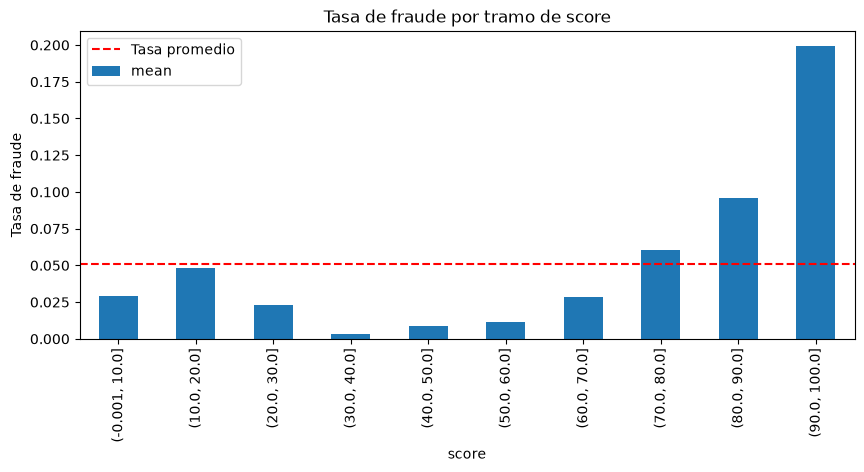

In [6]:
fraude_por_score["mean"].plot(kind="bar", figsize=(10, 4), title="Tasa de fraude por tramo de score")
plt.axhline(entrenamiento["fraude"].mean(), color="red", linestyle="--", label="Tasa promedio")
plt.ylabel("Tasa de fraude")
plt.legend()
plt.show()

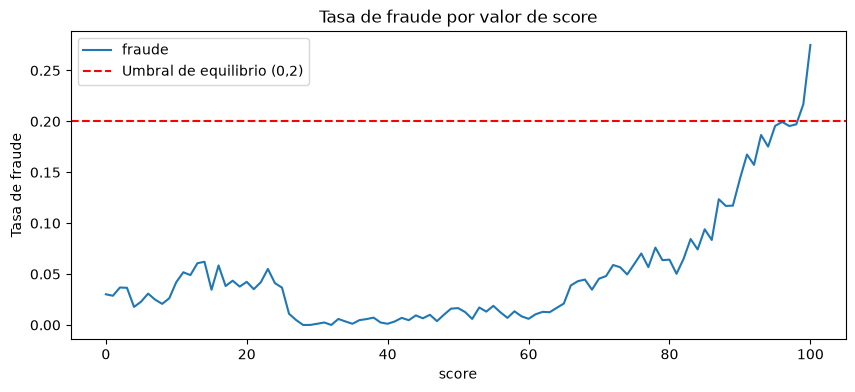

In [7]:
#Análisis por cada puntaje del score (1 a 1) - comparado con el umbral teorico que maximiza la ganancia
fraude_por_valor = entrenamiento.groupby("score")["fraude"].mean()

fraude_por_valor.plot(figsize=(10, 4), title="Tasa de fraude por valor de score")
plt.axhline(0.2, color="red", linestyle="--", label="Umbral de equilibrio (0,2)")
plt.ylabel("Tasa de fraude")
plt.legend()
plt.show()

### Conclusiones de la sección 3

**Observaciones:**
- El score funciona en dirección directa: un valor alto indica más riesgo. La tasa de fraude
  va de 0,3% en el tramo 30-40 a 20% en el tramo 90-100.
- No es ordenado en los valores bajos: entre 0 y 25 la tasa se mantiene entre 3% y 6%,
  cae bruscamente cerca de 25 y queda casi en cero hasta 60. El score actual tiene un punto ciego:
  una regla que rechace scores altos nunca atrapa ese fraude.
- Por transacción, la tasa supera el umbral de equilibrio (0,2) solo en los valores más altos
  (alrededor de 98). Rechazar todo el tramo 90-100, cuya tasa es 0,1997, dejaría una ganancia casi nula.

**Decisiones para el modelo:**
- El corte del benchmark se elegirá maximizando la ganancia en validación, porque la ganancia
  depende del monto y no solo de la cantidad de fraudes.
- Si el score se usa como variable, los modelos de árboles capturan su forma irregular;
  una regresión logística necesitaría transformarlo en tramos.
- El fraude de los scores bajos es una oportunidad concreta para que el modelo nuevo
  supere al score actual.

## 4. Variables numéricas y fraude

In [8]:
# Función para análizar las variables numericas vs el fraude
def tasa_por_tramos(datos, columna, q=10):
    #Tasa de fraude por decil de una variable numérica (nulos como aparte)
    tramos = pd.qcut(datos[columna], q=q, duplicates="drop")
    tabla = datos.groupby(tramos, observed=True)["fraude"].agg(["count", "mean"])
    tabla.index = tabla.index.astype(str)

    nulos = datos[datos[columna].isna()]
    if len(nulos) > 0:
        tabla.loc["nulo"] = [len(nulos), nulos["fraude"].mean()]
    return tabla

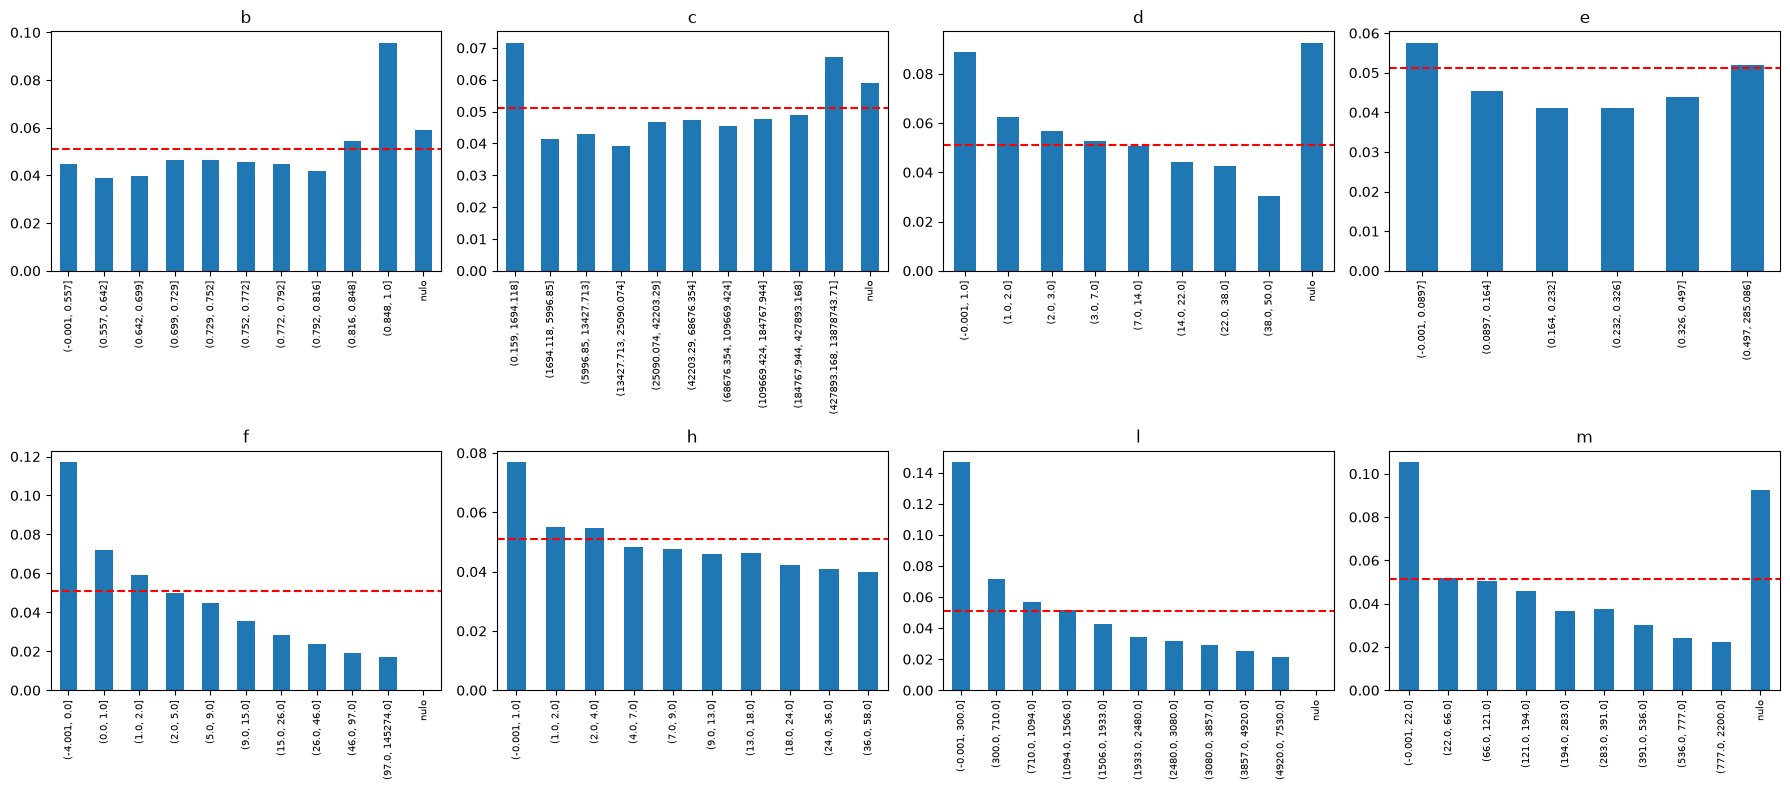

In [9]:
variables_numericas = ["b", "c", "d", "e", "f", "h", "l", "m"]
tasa_promedio = entrenamiento["fraude"].mean()

fig, ejes = plt.subplots(2, 4, figsize=(18, 8))
for columna, eje in zip(variables_numericas, ejes.flat):
    tasa_por_tramos(entrenamiento, columna)["mean"].plot(kind="bar", ax=eje, title=columna)
    eje.axhline(tasa_promedio, color="red", linestyle="--")
    eje.set_xlabel("")
    eje.tick_params(axis="x", labelsize=7)

plt.tight_layout()
plt.show()

In [10]:
# Analizando los nulos de las variables correpondietes
for columna in ["b", "d", "f"]:
    es_nulo = entrenamiento[columna].isna()
    print(
        f"{columna}: {es_nulo.sum()} nulos, "
        f"{entrenamiento.loc[es_nulo, 'fraude'].sum()} fraudes, "
        f"tasa {entrenamiento.loc[es_nulo, 'fraude'].mean() * 100:.1f}%"
    )

b: 12453 nulos, 736 fraudes, tasa 5.9%
d: 270 nulos, 25 fraudes, tasa 9.3%
f: 8 nulos, 0 fraudes, tasa 0.0%


In [11]:
# Detalle de la variable b (muchos nulos)
semana = entrenamiento["fecha"].dt.to_period("W")
nulos_b_semana = entrenamiento.groupby(semana)["b"].apply(lambda serie: serie.isna().mean() * 100).round(1)
nulos_b_semana

fecha
2020-03-02/2020-03-08     0.8
2020-03-09/2020-03-15    47.9
2020-03-16/2020-03-22     1.1
2020-03-23/2020-03-29     1.1
2020-03-30/2020-04-05     1.0
Freq: W-SUN, Name: b, dtype: float64

In [12]:
# Tasa de fraude en el incidente (ver si hay impacto)
semana_incidente = entrenamiento[semana == "2020-03-09/2020-03-15"]

(
    semana_incidente
    .groupby(semana_incidente["b"].isna())["fraude"]
    .agg(["count", "sum", "mean"])
    .rename(index={False: "b con dato", True: "b nulo"})
)

,count,sum,mean
b,,,
b con dato,12770,587,0.045967
b nulo,11753,597,0.050796


In [13]:
# Detalle dia por dia de la semana del incidente
(
    semana_incidente
    .groupby(semana_incidente["fecha"].dt.date)["b"]
    .apply(lambda serie: serie.isna().mean() * 100)
    .round(1)
)

fecha
2020-03-09     62.2
2020-03-10     42.3
2020-03-11     40.4
2020-03-12    100.0
2020-03-13     62.0
2020-03-14      1.2
2020-03-15      0.9
Name: b, dtype: float64

### Conclusiones de la sección 4

**Observaciones:**
- `f`, `l`, `m`, `d` y `h` muestran una relación decreciente: a menor valor, más fraude.
  `f`, `l` y `m` tienen el contraste más fuerte entre sus tramos extremos.
- `b` tiene más fraude solo en sus valores más altos, y `c` tiene forma de U
  (más fraude en los extremos).
- `e` casi no muestra relación con el fraude.
- Los nulos de `b` y `c` vienen casi todos de un incidente de datos: del 9 al 13 de marzo,
  entre 40% y 100% de las transacciones no registraron estas variables. El resto del periodo
  tienen alrededor de 1% de nulos. Dentro de esa semana, la tasa de fraude es similar con y sin dato
  (5,1% y 4,6%), lo que indica una falla mayormente aleatoria.
- Los nulos de `d` y `m` (270 transacciones, 25 fraudes) tienen una tasa de 9,3%, pero la muestra
  es pequeña para concluir. Los de `f` y `l` (8 transacciones) no permiten sacar conclusiones.

**Decisiones para el modelo:**
- Se conservan los nulos como valores faltantes: LightGBM los maneja de forma nativa.
- No se crea una variable indicadora de nulos para `b` y `c`, porque solo representaría
  el incidente, que no existe en producción.
- No se eliminan las filas del incidente, para no perder alrededor del 13% del entrenamiento.
- Para la regresión logística, las variables con formas irregulares (`b`, `c`) se transformarán
  en tramos, y los nulos se imputarán.
- Este incidente es un ejemplo de por qué en producción conviene monitorear
  el porcentaje de nulos por variable.

## 5. Variables categóricas y fraude

### 5.1 Variables de pocos valores

In [14]:
# Análisis de variables con pocos valores unicos (se incluyen a y n) 
#cantidad de trx por variable, cantidad de fraudes, tasa de fraude respectivamente y % de fraude
for columna in ["a", "n", "o", "p"]:
    tabla = entrenamiento.groupby(columna, dropna=False)["fraude"].agg(["count", "sum", "mean"])
    tabla["pct_fraudes"] = (tabla["sum"] / entrenamiento["fraude"].sum() * 100).round(1)
    print(f"--- {columna} ---")
    print(tabla, "\n")

--- a ---
   count   sum      mean  pct_fraudes
a                                    
1   2442   216  0.088452          4.7
2   9571   708  0.073973         15.4
3   1839   171  0.092985          3.7
4  76211  3512  0.046083         76.2 

--- n ---
   count   sum      mean  pct_fraudes
n                                    
0   8604  1450  0.168526         31.5
1  81459  3157  0.038756         68.5 

--- o ---
     count   sum      mean  pct_fraudes
o                                      
N    10150  2278  0.224433         49.4
Y    14643   961  0.065629         20.9
NaN  65270  1368  0.020959         29.7 

--- p ---
   count   sum      mean  pct_fraudes
p                                    
N  39791  3115  0.078284         67.6
Y  50272  1492  0.029679         32.4 



In [15]:
entrenamiento.groupby(semana)["o"].apply(lambda serie: serie.isna().mean() * 100).round(1)

fecha
2020-03-02/2020-03-08    71.5
2020-03-09/2020-03-15    72.7
2020-03-16/2020-03-22    72.6
2020-03-23/2020-03-29    72.5
2020-03-30/2020-04-05    72.0
Freq: W-SUN, Name: o, dtype: float64

**Observaciones:**
- `o` es la variable con la señal más fuerte: con `N`, la tasa de fraude es 22,4% y reúne
  casi la mitad de los fraudes en el 11% de las transacciones. Con `Y` es 6,6%, y cuando está vacía, 2,1%.
  El porcentaje de nulos es estable todas las semanas (alrededor de 72%), así que el vacío
  es parte del funcionamiento normal y tiene significado: indica menos riesgo.
- `n` también es muy fuerte: 16,9% de fraude con `0` frente a 3,9% con `1`.
- `p`: 7,8% de fraude con `N` frente a 3,0% con `Y`.
- `a`: el valor 4 (85% de las transacciones) tiene 4,6% de fraude y el resto entre 7,4% y 9,3%,
  sin un orden entre 1, 2 y 3.

**Decisiones para el modelo:**
- El nulo de `o` se trata como una categoría propia. No se imputa ni se elimina la variable.
- `a` no se trata como una escala en la regresión logística, sino como categorías.

### 5.2 Variables de muchos valores

In [16]:
principales = entrenamiento["g"].value_counts().head(5).index

grupo_pais = (
    entrenamiento["g"]
    .where(entrenamiento["g"].isin(principales), "otros")
    .mask(entrenamiento["g"].isna(), "nulo")
)

tabla_g = entrenamiento.groupby(grupo_pais)["fraude"].agg(["count", "sum", "mean"])
tabla_g["mean"] = (tabla_g["mean"] * 100).round(1)
tabla_g["pct_fraudes"] = (tabla_g["sum"] / entrenamiento["fraude"].sum() * 100).round(1)
tabla_g.sort_values("count", ascending=False)

,count,sum,mean,pct_fraudes
g,,,,
BR,67760,3797,5.6,82.4
AR,18747,731,3.9,15.9
UY,1680,16,1.0,0.3
US,1230,32,2.6,0.7
otros,379,20,5.3,0.4
SE,206,6,2.9,0.1
nulo,61,5,8.2,0.1


In [17]:
primer_periodo = entrenamiento["fecha"] < "2020-03-23"

tasas_1 = entrenamiento[primer_periodo].groupby("j")["fraude"].agg(["count", "mean"])
tasas_2 = entrenamiento[~primer_periodo].groupby("j")["fraude"].agg(["count", "mean"])

comparacion = tasas_1.join(tasas_2, lsuffix="_1", rsuffix="_2", how="inner")
comparacion = comparacion[(comparacion["count_1"] >= 50) & (comparacion["count_2"] >= 50)]

print(f"Categorías con al menos 50 transacciones en ambos periodos: {len(comparacion)}")
print(f"Correlación de la tasa de fraude entre periodos: {comparacion['mean_1'].corr(comparacion['mean_2']):.2f}")

conteo_j = entrenamiento["j"].value_counts()
raras = ~entrenamiento["j"].isin(conteo_j[conteo_j >= 10].index)
print(f"Tasa de fraude en categorías con menos de 10 transacciones: {entrenamiento.loc[raras, 'fraude'].mean() * 100:.1f}%")

Categorías con al menos 50 transacciones en ambos periodos: 100
Correlación de la tasa de fraude entre periodos: 0.66
Tasa de fraude en categorías con menos de 10 transacciones: 3.4%


**Observaciones (`g`, país):**
- Brasil concentra cerca del 82% de los fraudes, con una tasa de 5,6%.
  Argentina tiene una tasa menor (3,9%), con una muestra grande.
- Los demás países tienen muy pocos fraudes (entre 5 y 32), así que sus tasas no son confiables.

**Decisiones para el modelo:**
- Los países poco frecuentes se agrupan en "otros" con un umbral definido en entrenamiento, lo que también resuelve los países nuevos que aparezcan en producción.

**Observaciones (`j`):**
- Tiene una cola muy larga: las categorías con al menos 10 transacciones cubren el 82,2% de las transacciones, y las de al menos 50, apenas el 51,4%. Agrupar las raras en "otros"
  dejaría demasiadas transacciones en un solo grupo.
- El fraude se concentra en las categorías populares: las categorías con menos de 10 transacciones tienen 3,4% de fraude, frente al 5,1% promedio.
- Para medir la estabilidad, se dividió el conjunto de entrenamiento en dos periodos (antes y después del 23 de marzo). En las 100 categorías con al menos 50 transacciones en ambos periodos, la correlación de la tasa de fraude es 0,66: las categorías riesgosas tienden a seguir siéndolo.

**Decisiones para el modelo:**
- Se probarán dos codificaciones: por frecuencia (cuántas transacciones tiene la categoría)
  y por tasa de fraude. La segunda se calculará con validación cruzada dentro de entrenamiento para evitar fuga de información. Se elegirá comparando en validación.

## 6. Variables de tiempo

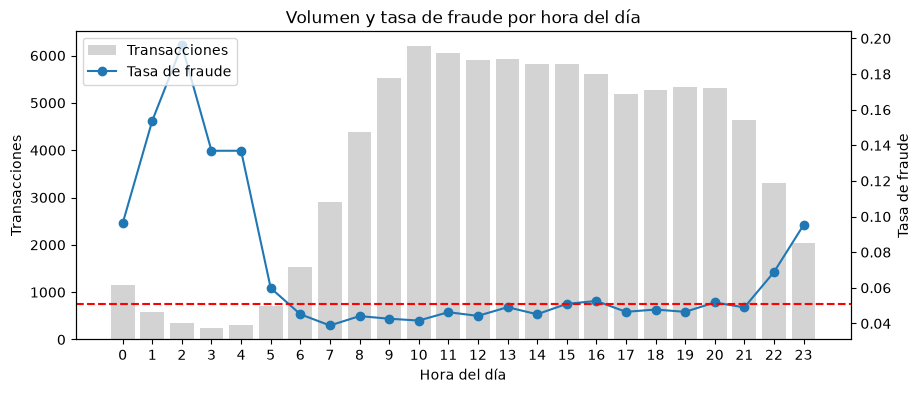

,count,sum,mean
fecha,,,
0,1143,110,0.096238
1,572,88,0.153846
2,352,69,0.196023
3,241,33,0.136929
4,314,43,0.136943
5,718,43,0.059889
6,1527,69,0.045187
7,2908,113,0.038858
8,4374,193,0.044124


In [18]:
hora = entrenamiento["fecha"].dt.hour
fraude_por_hora = entrenamiento.groupby(hora)["fraude"].agg(["count", "sum", "mean"])

fig, eje_volumen = plt.subplots(figsize=(10, 4))
eje_volumen.bar(fraude_por_hora.index, fraude_por_hora["count"], color="lightgray", label="Transacciones")
eje_volumen.set_xlabel("Hora del día")
eje_volumen.set_ylabel("Transacciones")

eje_tasa = eje_volumen.twinx()
eje_tasa.plot(fraude_por_hora.index, fraude_por_hora["mean"], color="tab:blue", marker="o", label="Tasa de fraude")
eje_tasa.axhline(entrenamiento["fraude"].mean(), color="red", linestyle="--")
eje_tasa.set_ylabel("Tasa de fraude")

eje_volumen.set_xticks(range(24))

lineas_1, etiquetas_1 = eje_volumen.get_legend_handles_labels()
lineas_2, etiquetas_2 = eje_tasa.get_legend_handles_labels()
eje_tasa.legend(lineas_1 + lineas_2, etiquetas_1 + etiquetas_2, loc="upper left")

plt.title("Volumen y tasa de fraude por hora del día")
plt.show()

fraude_por_hora

In [19]:
nocturna = hora.isin([22, 23, 0, 1, 2, 3, 4])

print(f"Transacciones nocturnas (22 a 4 h): {nocturna.mean() * 100:.1f}% del total")
print(f"Fraudes nocturnos: {entrenamiento.loc[nocturna, 'fraude'].sum() / entrenamiento['fraude'].sum() * 100:.1f}% del total")
print(f"Tasa de fraude nocturna: {entrenamiento.loc[nocturna, 'fraude'].mean() * 100:.1f}%")

Transacciones nocturnas (22 a 4 h): 8.8% del total
Fraudes nocturnos: 16.6% del total
Tasa de fraude nocturna: 9.6%


In [20]:
dia_semana = entrenamiento["fecha"].dt.dayofweek  # 0 = lunes, 6 = domingo
entrenamiento.groupby(dia_semana)["fraude"].agg(["count", "sum", "mean"])

,count,sum,mean
fecha,,,
0,14735,729,0.049474
1,14221,734,0.051614
2,13924,706,0.050704
3,13268,717,0.054040
4,11180,574,0.051342
5,9738,506,0.051961
6,12997,641,0.049319


**Observaciones (hora del día):**
- En la madrugada (0 a 4 horas) la tasa de fraude está entre 9,6% y 19,6%, con un máximo a las 2.
  Aunque el volumen es bajo, cada hora tiene entre 33 y 110 fraudes, así que la señal es confiable.
- En el horario diurno (6 a 21 horas) la tasa es estable, entre 3,9% y 5,3%.
- La franja de 22 a 4 horas concentra el 8,8% de las transacciones y el 16,6% de los fraudes
  (tasa de 9,6%). Aun así, el 83% del fraude ocurre de día: la hora ayuda, pero no basta sola.
- Supuesto: no se conoce la zona horaria de la fecha. Como Brasil y Argentina tienen horarios
  similares, el efecto debería ser pequeño.

**Decisiones para el modelo:**
- Los modelos de árboles usarán la hora directamente.
- Para la regresión logística se creará una variable de franja nocturna o se representará la hora
  de forma circular, porque las 23 y las 0 son horas consecutivas.

**Observaciones (día de la semana):**
- La tasa de fraude es similar todos los días (entre 4,9% y 5,4%).

**Decisión:** el día de la semana no se usará como variable.

## 7. Resumen de poder predictivo y revisión de fuga

In [21]:
def auc_univariada(datos, valores):
    """AUC de una variable frente al fraude, en su mejor dirección, y porcentaje de filas con dato."""
    con_dato = valores.notna()
    auc = roc_auc_score(datos.loc[con_dato, "fraude"], valores[con_dato])
    return max(auc, 1 - auc), con_dato.mean() * 100

variables = {}

# Numéricas: se usan como son
for columna in ["b", "c", "d", "e", "f", "h", "l", "m", "monto", "score", "k"]:
    variables[columna] = entrenamiento[columna]

# Categóricas y hora: cada valor se reemplaza por su tasa de fraude (nulos como categoría)
hora_texto = entrenamiento["fecha"].dt.hour.astype("string").rename("hora")
for serie in [entrenamiento[c] for c in ["a", "n", "o", "p", "g"]] + [hora_texto]:
    categoria = serie.astype("string").fillna("nulo")
    variables[serie.name] = categoria.map(entrenamiento.groupby(categoria)["fraude"].mean())

# j: por su frecuencia, para no sobreajustar sus miles de categorías
variables["j (frecuencia)"] = entrenamiento["j"].map(entrenamiento["j"].value_counts())

resultados = pd.DataFrame(
    [(nombre, *auc_univariada(entrenamiento, valores)) for nombre, valores in variables.items()],
    columns=["variable", "auc", "cobertura_pct"],
).sort_values("auc", ascending=False)
resultados.round(3)

,variable,auc,cobertura_pct
13,o,0.755,100.000
9,score,0.724,100.000
4,f,0.687,99.991
6,l,0.675,99.991
7,m,0.658,99.700
14,p,0.623,100.000
12,n,0.616,100.000
2,d,0.612,99.700
17,j (frecuencia),0.568,100.000
5,h,0.565,100.000


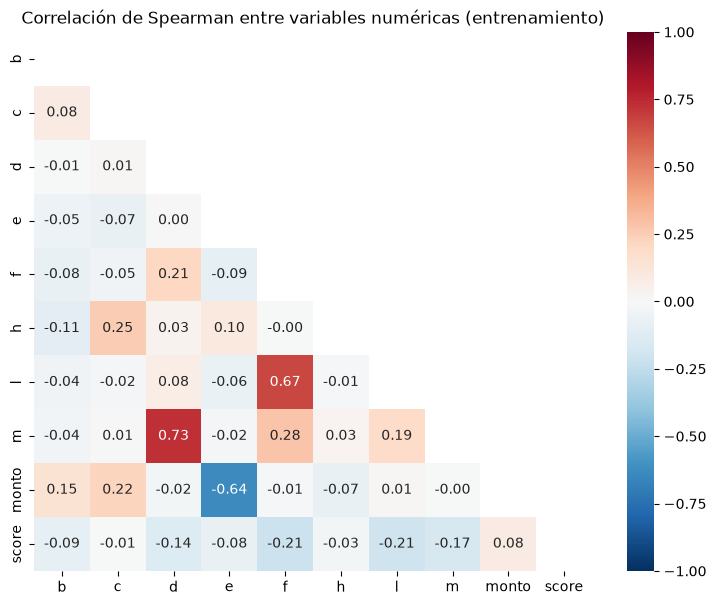

In [22]:
# Análisis de correlación
numericas = ["b", "c", "d", "e", "f", "h", "l", "m", "monto", "score"]
correlaciones = entrenamiento[numericas].corr(method="spearman")

# Oculta la mitad superior, que repite la información de la inferior
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlaciones,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
)
plt.title("Correlación de Spearman entre variables numéricas (entrenamiento)")
plt.show()

In [23]:
#Analisis bivariado de K
segmentos = {
    "Brasil": entrenamiento["g"] == "BR",
    "Argentina": entrenamiento["g"] == "AR",
    "o = N": entrenamiento["o"] == "N",
    "n = 0": entrenamiento["n"] == 0,
}

for nombre, filtro in segmentos.items():
    datos = entrenamiento[filtro]
    auc = roc_auc_score(datos["fraude"], datos["k"])
    print(f"{nombre}: AUC de k = {max(auc, 1 - auc):.3f} ({datos['fraude'].sum()} fraudes)")

Brasil: AUC de k = 0.505 (3797 fraudes)
Argentina: AUC de k = 0.503 (731 fraudes)
o = N: AUC de k = 0.502 (2278 fraudes)
n = 0: AUC de k = 0.508 (1450 fraudes)


### 7.1 Criterio para evaluar redundancia entre variables

Se usa la correlación de Spearman porque varias variables tienen valores extremos
(ver el control de calidad del notebook 01) y porque la relación entre dos variables
puede ser curva en lugar de recta, como parece ocurrir entre `e` y `monto`.
Spearman trabaja con el orden de los valores, así que no se ve afectada por los extremos
y capta cualquier relación que siempre suba o siempre baje.

| Correlación (valor absoluto) | Interpretación | Decisión |
|---|---|---|
| Menor a 0,3 | Débil | Se conservan ambas variables. |
| Entre 0,3 y 0,75 | Moderada | Se conservan ambas. En la regresión logística se aplica regularización. |
| Entre 0,75 y 0,9 | Fuerte | Se evalúa quitar una, comparando la ganancia en validación con y sin ella. |
| Mayor a 0,9 | Casi duplicadas | Se conserva solo una: la de mayor poder predictivo o con menos nulos. |

Estos umbrales son convenciones habituales, no reglas exactas. La decisión final
sobre una variable se valida en el conjunto de validación, comparando la ganancia del modelo.

### Conclusiones de la sección 7

**Observaciones:**
- Las variables con mayor poder predictivo individual son `o` (AUC 0,755), el `score` (0,724),
  `f` (0,687), `l` (0,675) y `m` (0,658).
- Ninguna variable tiene un poder predictivo sospechosamente alto, así que no hay señales
  de fuga de información.
- `k` no tiene relación con el fraude (AUC 0,503), se calculó su AUC dentro de los segmentos con más fraude.
En todos queda entre 0,502 y 0,508. Junto con su distribución uniforme, sus valores únicos por fila y su falta de relación con la fecha, se concluye
que se comporta como un identificador.
- `monto` tiene un AUC bajo (0,556) pero concentra la pérdida económica: el AUC cuenta
  transacciones, no dinero. Por eso el modelo se evaluará en ganancia.
- `c` aparece casi sin poder (0,505), pero su relación con el fraude tiene forma de U,
  que el AUC no capta.
- Las parejas `d`/`m` (0,73) y `f`/`l` (0,67) están correlacionadas.
- `e` y `monto` tienen una correlación negativa (-0,64), lo que refuerza la hipótesis
  de que `e` es un cociente que depende del monto.
- El `score` está poco correlacionado con las demás variables: aporta información distinta.

**Decisiones para el modelo:**
- Se excluye `k` (No tiene correlacion con ninguna otra). No se elimina ninguna otra variable por redundancia, porque ningún par
  supera 0,75 de correlación.
- La regresión logística usará regularización para manejar las variables correlacionadas.
- Se evaluará incluir el `score` como variable, ya que complementa a las demás.

## 8. Estabilidad en el tiempo de las variables principales

In [24]:
principales = ["o", "score", "f", "l", "m", "p", "n"]
estabilidad = {}

for nombre_semana, datos_semana in entrenamiento.groupby(semana):
    fila = {}
    for nombre in principales:
        valores = variables[nombre].loc[datos_semana.index]
        fila[nombre] = auc_univariada(datos_semana, valores)[0]
    estabilidad[str(nombre_semana)] = fila

pd.DataFrame(estabilidad).T.round(3)

,o,score,f,l,m,p,n
2020-03-02/2020-03-08,0.735,0.764,0.714,0.703,0.659,0.637,0.642
2020-03-09/2020-03-15,0.750,0.718,0.682,0.672,0.652,0.616,0.614
2020-03-16/2020-03-22,0.766,0.716,0.701,0.683,0.663,0.626,0.617
2020-03-23/2020-03-29,0.754,0.732,0.693,0.671,0.663,0.630,0.623
2020-03-30/2020-04-05,0.754,0.733,0.665,0.671,0.650,0.619,0.604


### Conclusiones de la sección 8

**Observaciones:**
- El poder predictivo de las variables principales es estable semana a semana. Por ejemplo, `o` se mantiene entre 0,750 y 0,766
  y el `score` entre 0,716 y 0,733.
- El orden de importancia de las variables no cambia entre semanas.
- La estabilidad se mantiene incluso en las semanas afectadas por COVID, con menos volumen y más fraude.
- `f` y `n` bajan levemente en la última semana (unas 0,03 y 0,02), pero son las primeras variables a vigilar en validación.

**Decisión para el modelo:**
- No se descarta ninguna variable por inestabilidad. En producción, el monitoreo
  del poder predictivo por variable permitiría detectar si alguna empieza a perder su relación
  con el fraude.

## 9. Conclusiones y decisiones para el modelo

### Hallazgos principales
- **El fraude se concentra en el dinero:** el 10% de las compras más caras explica el 70,6%
  de la pérdida, y el 0,5% de los fraudes explica el 11,8%.
- **El score actual funciona, pero tiene un punto ciego:** detecta bien el riesgo en valores altos,
  pero no el fraude de los scores bajos (entre 0 y 25).
- **Las variables más predictivas** son `o`, el `score`, `f`, `l` y `m`, y su poder es estable
  semana a semana, incluso en el periodo afectado por el COVID.
- **Hay un incidente de datos:** entre el 9 y el 13 de marzo, `b` y `c` dejaron de registrarse
  en buena parte de las transacciones.
- **No hay señales de fuga de información** ni variables redundantes.

### Tratamiento de cada variable

| Variable | Decisión |
|---|---|
| `monto` | Se usa. También se probará como peso del entrenamiento, con un límite. |
| `score` | Se entrenarán dos versiones del modelo: sin el score (escenario en que lo reemplaza) y con el score (escenario en que lo complementa). |
| `o` | Se usa con tres categorías: `Y`, `N` y nulo. |
| `n`, `p` | Se usan tal cual (binarias). |
| `a` | Se usa como categoría, no como escala. |
| `g` | Los países poco frecuentes se agrupan en "otros". |
| `j` | Se probarán codificación por frecuencia y por tasa de fraude suavizada. |
| `b`, `c` | Se usan. Los nulos se conservan como faltantes, sin indicador del incidente. |
| `d`, `f`, `h`, `l`, `m`, `e` | Se usan. Los nulos se conservan como faltantes. |
| Hora | Se crea a partir de la fecha. |
| Día de la semana | Se descarta: no muestra relación con el fraude. |
| `k` | Se excluye: se comporta como un identificador. |
| `fecha` | Solo se usa para separar los datos, no como variable. |

### Evaluación del modelo
- La métrica principal será la **ganancia**. Como apoyo: porcentaje del monto de fraude evitado,
  precisión en monto de las transacciones rechazadas y tasa de aprobación.
- El umbral teórico es 0,2. Se comparará con el umbral que maximiza la ganancia en validación.
- Se comparará una escalera de referencias: aprobar todo, el score actual con su mejor corte,
  una regresión logística y un modelo de boosting.
- Como pocas transacciones explican mucha pérdida, la comparación entre modelos se hará
  midiendo la variabilidad de la ganancia (bootstrap).
- La exclusión de `k` se confirmará comparando la ganancia en validación.
- Como el enunciado no indica si el modelo reemplaza o complementa al score actual,
  se reportarán ambos escenarios.